# 1D CNN – Oil production forecasting 

1. Load and preprocess data
2. Build sliding-window sequences
3. Build and fit the 1D CNN
4. Evaluate on the test set

1. Load and preprocess data

In [51]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [52]:
# Read data and keep well NO 15/9-F-12 H (selected in EDA)
data_path = Path("../data/Raw_prod_data.xlsx")
df = pd.read_excel(data_path)
df = df[df["WELL_BORE_CODE"] == "NO 15/9-F-12 H"].sort_values("DATEPRD").reset_index(drop=True)

features = ['ON_STREAM_HRS', 'AVG_DOWNHOLE_PRESSURE', 'AVG_DOWNHOLE_TEMPERATURE', 'AVG_DP_TUBING',
            'AVG_ANNULUS_PRESS', 'AVG_CHOKE_SIZE_P', 'AVG_WHP_P', 'AVG_WHT_P', 'DP_CHOKE_SIZE']
target = 'BORE_OIL_VOL'

df = df[['DATEPRD'] + features + [target]].drop_duplicates()
print("Dimension: ", df.shape)
print(df.isna().sum())

Dimension:  (3056, 11)
DATEPRD                      0
ON_STREAM_HRS                0
AVG_DOWNHOLE_PRESSURE        6
AVG_DOWNHOLE_TEMPERATURE     6
AVG_DP_TUBING                6
AVG_ANNULUS_PRESS           13
AVG_CHOKE_SIZE_P            44
AVG_WHP_P                    0
AVG_WHT_P                    0
DP_CHOKE_SIZE                0
BORE_OIL_VOL                 0
dtype: int64


In [53]:
# Handle missing values: linear interpolation over time, then fill the edges
df[features] = df[features].interpolate(method="linear").ffill().bfill()
print("Remaining missing values:", df.isna().sum().sum())

Remaining missing values: 0


2. Build sliding-window sequences

In [54]:
# Chronological split: 70% train, 15% validation, 15% test
n = len(df)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

# Fit scalers on the training period only to avoid leakage
cols = features + [target]
x_scaler = MinMaxScaler().fit(df[cols].iloc[:train_end])
y_scaler = MinMaxScaler().fit(df[[target]].iloc[:train_end])

X_all = x_scaler.transform(df[cols])
y_all = y_scaler.transform(df[[target]]).ravel()

In [55]:
# Each sample uses the previous WINDOW days (all features + past oil volume) to predict the next day's oil volume
WINDOW = 30

def make_sequences(X, y, window):
    Xs, ys, idx = [], [], []
    for t in range(window, len(X)):
        Xs.append(X[t - window:t])
        ys.append(y[t])
        idx.append(t)
    return np.array(Xs), np.array(ys), np.array(idx)

X_seq, y_seq, t_idx = make_sequences(X_all, y_all, WINDOW)

# Assign each sample to a split by the date of its target
train_mask = t_idx < train_end
val_mask = (t_idx >= train_end) & (t_idx < val_end)
test_mask = t_idx >= val_end

X_train, y_train = X_seq[train_mask], y_seq[train_mask]
X_val, y_val = X_seq[val_mask], y_seq[val_mask]
X_test, y_test = X_seq[test_mask], y_seq[test_mask]

print("Train:", X_train.shape, "Val:", X_val.shape, "Test:", X_test.shape)

Train: (2109, 30, 10) Val: (458, 30, 10) Test: (459, 30, 10)


3. Build and fit the 1D CNN

In [56]:
def build_cnn(window, n_features):
    model = keras.Sequential([
        layers.Input(shape=(window, n_features)),
        layers.Conv1D(64, kernel_size=3, padding="causal", activation="relu"),
        layers.Conv1D(64, kernel_size=3, padding="causal", activation="relu"),
        layers.MaxPooling1D(pool_size=2),
        layers.Conv1D(32, kernel_size=3, padding="causal", activation="relu"),
        layers.Flatten(),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.2),
        layers.Dense(1),
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss="mse", metrics=["mae"])
    return model

model = build_cnn(WINDOW, X_train.shape[2])
model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_15 (Conv1D)              │ (None, 30, 64)         │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_16 (Conv1D)              │ (None, 30, 64)         │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_5 (MaxPooling1D)  │ (None, 15, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_17 (Conv1D)              │ (None, 15, 32)         │         6,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 480)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │        30,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 51,361 (200.63 KB)

 Trainable params: 51,361 (200.63 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=8, min_lr=1e-5),
]

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=200,
    batch_size=32,
    shuffle=True,
    callbacks=callbacks,
    verbose=2,
)

Epoch 1/200
66/66 - 1s - 19ms/step - loss: 0.0395 - mae: 0.1298 - val_loss: 0.0018 - val_mae: 0.0328 - learning_rate: 0.0010
Epoch 2/200
66/66 - 0s - 4ms/step - loss: 0.0191 - mae: 0.0873 - val_loss: 0.0014 - val_mae: 0.0306 - learning_rate: 0.0010
Epoch 3/200
66/66 - 0s - 4ms/step - loss: 0.0175 - mae: 0.0838 - val_loss: 9.0603e-04 - val_mae: 0.0238 - learning_rate: 0.0010
Epoch 4/200
66/66 - 0s - 4ms/step - loss: 0.0157 - mae: 0.0768 - val_loss: 7.0620e-04 - val_mae: 0.0206 - learning_rate: 0.0010
Epoch 5/200
66/66 - 0s - 4ms/step - loss: 0.0142 - mae: 0.0717 - val_loss: 6.4595e-04 - val_mae: 0.0177 - learning_rate: 0.0010
Epoch 6/200
66/66 - 0s - 4ms/step - loss: 0.0135 - mae: 0.0724 - val_loss: 6.0307e-04 - val_mae: 0.0176 - learning_rate: 0.0010
Epoch 7/200
66/66 - 0s - 4ms/step - loss: 0.0129 - mae: 0.0697 - val_loss: 5.1708e-04 - val_mae: 0.0157 - learning_rate: 0.0010
Epoch 8/200
66/66 - 0s - 4ms/step - loss: 0.0116 - mae: 0.0662 - val_loss: 5.8350e-04 - val_mae: 0.0162 - learn

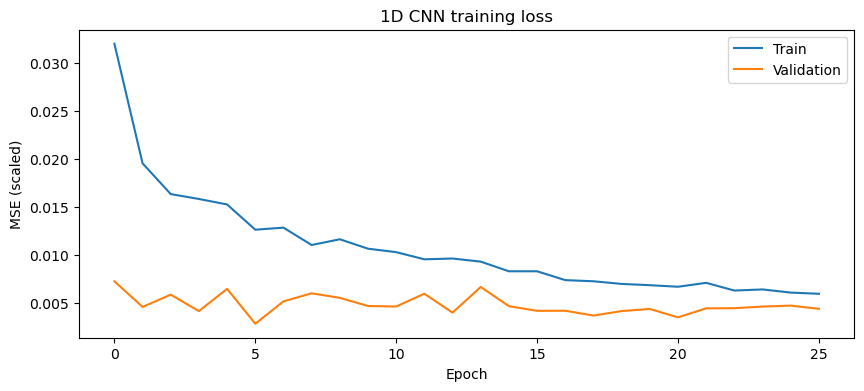

In [ ]:
# Learning curves
plt.figure(figsize=(10, 4))
plt.plot(history.history["loss"], label="Train")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("1D CNN training loss")
plt.xlabel("Epoch")
plt.ylabel("MSE (scaled)")
plt.legend()
plt.show()

4. Evaluate on the test set

In [ ]:
def evaluate(X, y_scaled, name):
    y_pred = y_scaler.inverse_transform(model.predict(X, verbose=0)).ravel()
    y_true = y_scaler.inverse_transform(y_scaled.reshape(-1, 1)).ravel()
    y_pred = np.clip(y_pred, 0, None)  # production cannot be negative
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"{name:<10} RMSE: {rmse:8.2f}  MAE: {mae:8.2f}  R2: {r2:.3f}")
    return y_true, y_pred

evaluate(X_train, y_train, "Train")
evaluate(X_val, y_val, "Validation")
y_true_test, y_pred_test = evaluate(X_test, y_test, "Test")

Train      RMSE:   557.96  MAE:   329.08  R2: 0.900
Validation RMSE:   315.96  MAE:   243.48  R2: -0.292
Test       RMSE:   215.40  MAE:   177.70  R2: -0.580


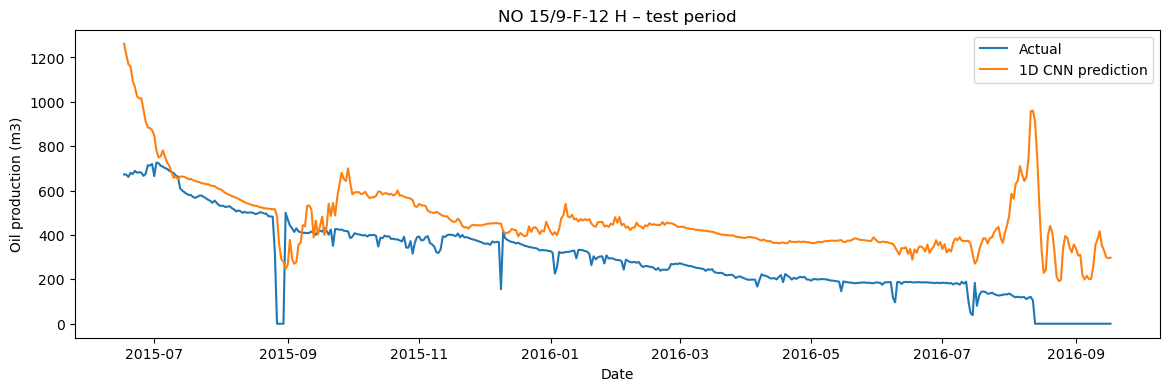

In [ ]:
# Actual vs predicted on the test period
test_dates = df["DATEPRD"].iloc[t_idx[test_mask]]

plt.figure(figsize=(14, 4))
plt.plot(test_dates, y_true_test, label="Actual")
plt.plot(test_dates, y_pred_test, label="1D CNN prediction")
plt.title("NO 15/9-F-12 H – test period")
plt.xlabel("Date")
plt.ylabel("Oil production (m3)")
plt.legend()
plt.show()